# **Comparing Multi-Object Tracking (MOT) Algorithms for Stable Real-Time YOLOv8 Tracking**

Jerome Loke | 2026  
Reproducible experimental companion to the technical report

This notebook is the reproducible experimental companion to the technical paper. It keeps the YOLOv8 detector, video, preprocessing, evaluation rules, and hardware fixed while changing only the multi-object tracker.

## Abstract

Prerequisites for stable pedestrian tracking go beyond detecting people in each video frame. A real-time system needs to retain pedestrian IDs through overlaps, occlusions, missed detections and sudden changes in motion.  
This notebook presents a controlled comparison of 5 MOT algorithms: ByteTrack, BoT-SORT (Bag of Tricks for SORT), TrackTrack, Deep OC-SORT + ReID, and FastTrack, using the same YOLOv8l detector and [MOT17-09 input sequence](https://arxiv.org/abs/2010.07548).  
Tracking quality is measured using HOTA, DetA, AssA, IDF1, MOTA, IDSW (ID switches), fragmentation, and precision/recall.  
Performance is measured using median latency, P95 latency and throughput (FPS).
The executed comparison distinguishes the tracker with the strongest identity and overall tracking quality from the tracker with the highest throughput, making the quality-speed trade-off explicit for laptop deployment. This work does not propose a new tracker; its contribution is a reproducible implementation comparison of advanced association strategies under one fixed detection pipeline.

## 1 Introduction

YOLO performs spatial detection: it locates people independently in each frame. Multi-object tracking adds a temporal association problem by deciding which detection belongs to which existing trajectory. Persistent IDs enable crowd counting, trajectory analysis, dwell-time measurement, and alerts, but can fail when pedestrians overlap or temporarily disappear.

The engineering objective is not accuracy alone. Appearance matching and richer association logic may improve identity stability, but can also increase latency and affect whether a tracker meets a 30 FPS real-time target. The research question is therefore:

> **How do five multi-object tracking algorithms compare in tracking stability and real-time performance when paired with the same YOLOv8 object detector?**

The experiment holds YOLOv8l, the person-only class filter, confidence threshold, image size, preprocessing, input frames, ground truth, and metric implementation constant. Only the tracker configuration changes.

| Part C evaluation criterion | Notebook evidence |
|---|---|
| Review of research articles | Section 2 explains and cites each association strategy |
| Dataset | Section 3.2 validates MOT17-09 and visualises its ground truth |
| Advanced models | Section 3.1 compares five modern tracking algorithms under one detector |
| Evaluation and discussion | Section 4 reports quality, identity, errors, latency, and qualitative behaviour |
| Appropriate topic level | The work extends frame-level CNN detection into temporal association and ReID |

## 2 Related Work

**ByteTrack** uses a second association stage for lower-confidence detections instead of discarding them immediately. This can recover partially occluded pedestrians while keeping the tracker lightweight [1]. **BoT-SORT** combines motion, detection confidence, camera-motion compensation, and optional appearance information to improve robust association [2].

**TrackTrack** focuses association decisions on the history of each track and suppresses spurious initialisation where detections overlap active tracks [3]. **Deep OC-SORT** extends observation-centric motion correction with adaptively weighted appearance features; this experiment explicitly enables its ReID path [4]. **FastTrack** extends ByteTrack-style association with occlusion detection, Kalman-state rollback, and longer recovery windows while avoiding a separate appearance model [5].

These papers report results under different detectors, datasets, configurations, and hardware. This notebook asks a narrower deployment question: what happens when all five trackers process identical detections on the same laptop?

| Tracker | Main association idea | ReID in this experiment | Expected trade-off |
|---|---|---:|---|
| ByteTrack | High- and low-score detection association | No | Strong speed baseline |
| BoT-SORT | Motion, confidence, and camera compensation | No | Richer association with additional latency |
| TrackTrack | Iterative track-focused multi-cue assignment | No | Strong crowd association and duplicate suppression |
| Deep OC-SORT | Observation-centric motion plus appearance | Yes | Better recovery using ReID, with additional appearance-processing cost |
| FastTrack | Occlusion-aware rollback and recovery | No | Lightweight crowd-occlusion handling |

## 3 Dataset, System and Methodology

### 3.1 Fixed detection pipeline and tracker variants

Every run uses the same pretrained YOLOv8l detector, COCO person class (`0`), confidence threshold (`0.10`), inference size (`640`), and Gaussian blur. Each tracker receives a fresh `Detector` and processes all frames in order with `persist=True`. The neutral brightness setting used by `experiment.py` has an offset of zero, so the notebook omits that no-op pixel addition without changing the input.

Runtime begins immediately before frame reading and ends after tracking results are transferred for collection. Rendering and MP4 encoding happen after the timer, so the reported latency compares capture, preprocessing, detection, and tracking rather than display cost.

In [1]:
from pathlib import Path
import platform
import subprocess
import sys
import time

import cv2
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import linear_sum_assignment
import torch
import ultralytics
from IPython.display import Markdown, display
from ultralytics.utils.checks import check_yaml

import config
from detector import Detector

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

In [2]:
VIDEO_PATH = Path("evaluation/stationary_webcam_eval.mp4")
GROUND_TRUTH_PATH = Path("evaluation/ground_truth.txt")
OUTPUT_DIR = Path("evaluation/results")
FIGURE_DIR = OUTPUT_DIR / "figures"

EVALUATED_CLASS_IDS = (0,)  # COCO person class
TRACKERS = {
    "ByteTrack": "bytetrack.yaml",
    "BoT-SORT": "botsort.yaml",
    "TrackTrack": "tracktrack.yaml",
    "Deep OC-SORT + ReID": "trackers/deepocsort_reid.yaml",
    "FastTrack": "fasttrack.yaml",
}

DETECTION_CONFIDENCE = 0.10
MATCH_IOU = 0.50
WARMUP_FRAMES = 5
SAVE_ANNOTATED_VIDEO = True
HOTA_ALPHAS = np.arange(0.05, 0.96, 0.05)

EXPECTED_FRAMES = 525
EXPECTED_ANNOTATIONS = 5_325
EXPECTED_IDENTITIES = 26

PREDICTION_COLUMNS = [
    "frame", "track_id", "x", "y", "width", "height", "confidence", "class_id"
]

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
required_files = [VIDEO_PATH, GROUND_TRUTH_PATH, Path(config.MODEL_PATH)]
missing_files = [str(path) for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(f"Missing experiment files: {missing_files}")

resolved_tracker_configs = {
    name: str(check_yaml(tracker_config))
    for name, tracker_config in TRACKERS.items()
}

device = "cuda:0" if torch.cuda.is_available() else "cpu"
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only"
git_commit = subprocess.run(
    ["git", "rev-parse", "HEAD"], capture_output=True, text=True, check=False
).stdout.strip() or "Unavailable"

environment = pd.Series({
    "Git commit": git_commit,
    "Python": platform.python_version(),
    "PyTorch": torch.__version__,
    "CUDA runtime": torch.version.cuda or "Not available",
    "Ultralytics": ultralytics.__version__,
    "OpenCV": cv2.__version__,
    "NumPy": np.__version__,
    "pandas": pd.__version__,
    "SciPy": scipy.__version__,
    "Matplotlib": matplotlib.__version__,
    "Device": device,
    "GPU": gpu_name,
    "Processor": platform.processor() or "Unavailable",
}, name="Value").to_frame()

display(environment)
display(pd.Series(TRACKERS, name="Tracker configuration").to_frame())

,Value
Git commit,d69294f76f0a5cba4189022a454b05a2f2a5dfdb
Python,3.13.5
PyTorch,2.14.0.dev20260612+cu132
CUDA runtime,13.2
Ultralytics,8.4.67
OpenCV,4.13.0
NumPy,2.3.1
pandas,2.3.0
SciPy,1.16.3
Matplotlib,3.10.3


,Tracker configuration
ByteTrack,bytetrack.yaml
BoT-SORT,botsort.yaml
TrackTrack,tracktrack.yaml
Deep OC-SORT + ReID,trackers/deepocsort_reid.yaml
FastTrack,fasttrack.yaml


### 3.2 Evaluation dataset and preprocessing

The input is **MOT17-09**, a low-angle pedestrian street sequence from MOTChallenge. It contains 525 frames at 1920×1080 and 30 FPS, with 5,325 valid pedestrian annotations across 26 identities [7]. Ground truth uses MOTChallenge rows of `frame, id, x, y, width, height, confidence, class, visibility`; tracker output is converted to the same top-left/width/height representation.

The evaluator retains valid pedestrian annotations but does not implement official distractor and ignore-region handling. The values below are therefore controlled local comparison results, not official MOTChallenge benchmark submissions.

In [4]:
column_names = [
    "frame", "track_id", "x", "y", "width", "height",
    "confidence", "class_id", "visibility"
]
raw_ground_truth = pd.read_csv(
    GROUND_TRUTH_PATH,
    header=None,
    comment="#",
    sep=r"[,\s]+",
    engine="python",
)
if raw_ground_truth.shape[1] < 6:
    raise ValueError("Ground truth needs at least frame,id,x,y,width,height")

raw_ground_truth = raw_ground_truth.iloc[:, : len(column_names)]
raw_ground_truth.columns = column_names[: raw_ground_truth.shape[1]]
numeric_columns = ["frame", "track_id", "x", "y", "width", "height"]
for column in numeric_columns:
    raw_ground_truth[column] = pd.to_numeric(raw_ground_truth[column], errors="raise")
if "confidence" in raw_ground_truth:
    raw_ground_truth = raw_ground_truth[
        pd.to_numeric(raw_ground_truth["confidence"], errors="raise") > 0
    ]

raw_ground_truth["frame"] = raw_ground_truth["frame"].astype(int)
raw_ground_truth["track_id"] = raw_ground_truth["track_id"].astype(int)
if raw_ground_truth.empty:
    raise ValueError("Ground truth contains no evaluable rows")
if (raw_ground_truth["frame"] < 1).any() or (
    raw_ground_truth[["width", "height"]] <= 0
).any().any():
    raise ValueError("Frames must be 1-based and all boxes must have positive size")

ground_truth_full = raw_ground_truth.sort_values(
    ["frame", "track_id"]
).reset_index(drop=True)
ground_truth = ground_truth_full[numeric_columns].copy()

capture = cv2.VideoCapture(str(VIDEO_PATH), cv2.CAP_ANY)
if not capture.isOpened():
    raise RuntimeError(f"Could not open {VIDEO_PATH}")
video_metadata = {
    "Sequence": "MOT17-09",
    "Frames": int(capture.get(cv2.CAP_PROP_FRAME_COUNT)),
    "Width": int(capture.get(cv2.CAP_PROP_FRAME_WIDTH)),
    "Height": int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT)),
    "FPS": float(capture.get(cv2.CAP_PROP_FPS)),
    "Valid pedestrian annotations": len(ground_truth),
    "Pedestrian identities": ground_truth["track_id"].nunique(),
    "Mean pedestrians per frame": len(ground_truth) / ground_truth["frame"].nunique(),
}
capture.release()

assert video_metadata["Frames"] == EXPECTED_FRAMES
assert video_metadata["Valid pedestrian annotations"] == EXPECTED_ANNOTATIONS
assert video_metadata["Pedestrian identities"] == EXPECTED_IDENTITIES
display(pd.Series(video_metadata, name="Value").to_frame())

,Value
Sequence,MOT17-09
Frames,525
Width,1920
Height,1080
FPS,30.0
Valid pedestrian annotations,5325
Pedestrian identities,26
Mean pedestrians per frame,10.142857


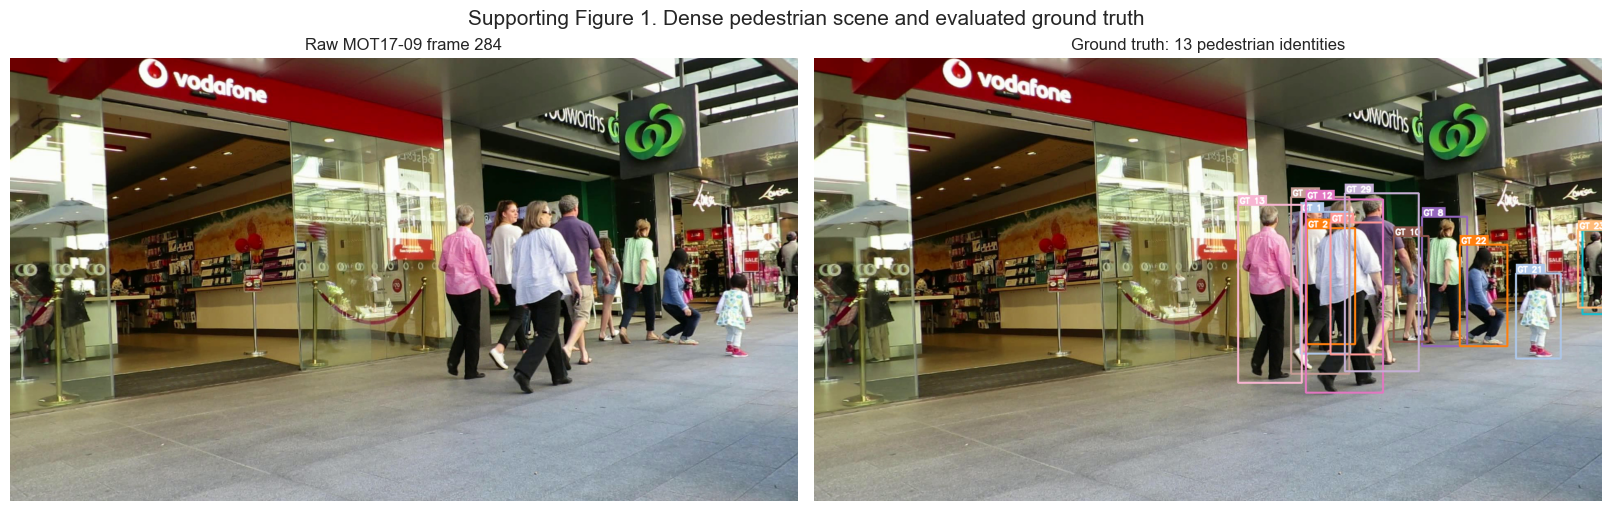

Saved evaluation\results\figures\figure_1_dataset_ground_truth.png


In [5]:
def read_video_frame(frame_number: int) -> np.ndarray:
    capture = cv2.VideoCapture(str(VIDEO_PATH), cv2.CAP_ANY)
    capture.set(cv2.CAP_PROP_POS_FRAMES, frame_number - 1)
    ok, frame = capture.read()
    capture.release()
    if not ok:
        raise ValueError(f"Could not read frame {frame_number}")
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)


def identity_color(track_id: int) -> tuple[int, int, int]:
    rgb = plt.get_cmap("tab20")(int(track_id) % 20)[:3]
    return tuple(int(channel * 255) for channel in rgb)


def draw_track_boxes(
    image: np.ndarray,
    rows: pd.DataFrame,
    label_prefix: str,
) -> np.ndarray:
    annotated = image.copy()
    for row in rows.itertuples():
        x1, y1 = int(row.x), int(row.y)
        x2, y2 = int(row.x + row.width), int(row.y + row.height)
        color = identity_color(int(row.track_id))
        cv2.rectangle(annotated, (x1, y1), (x2, y2), color, 3)
        label = f"{label_prefix} {int(row.track_id)}"
        (text_w, text_h), _ = cv2.getTextSize(
            label, cv2.FONT_HERSHEY_SIMPLEX, 0.65, 2
        )
        text_y = max(y1, text_h + 8)
        cv2.rectangle(
            annotated,
            (x1, text_y - text_h - 8),
            (x1 + text_w + 8, text_y + 2),
            color,
            -1,
        )
        cv2.putText(
            annotated,
            label,
            (x1 + 4, text_y - 3),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (255, 255, 255),
            2,
            cv2.LINE_AA,
        )
    return annotated


dataset_frame_number = 284
dataset_frame = read_video_frame(dataset_frame_number)
dataset_boxes = ground_truth[
    ground_truth["frame"] == dataset_frame_number
]
assert len(dataset_boxes) == 13
dataset_annotated = draw_track_boxes(dataset_frame, dataset_boxes, "GT")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), constrained_layout=True)
axes[0].imshow(dataset_frame)
axes[0].set_title("Raw MOT17-09 frame 284")
axes[1].imshow(dataset_annotated)
axes[1].set_title("Ground truth: 13 pedestrian identities")
for axis in axes:
    axis.axis("off")
fig.suptitle("Supporting Figure 1. Dense pedestrian scene and evaluated ground truth", fontsize=15)
figure_1_path = FIGURE_DIR / "figure_1_dataset_ground_truth.png"
fig.savefig(figure_1_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved {figure_1_path}")

**Supporting Figure 1.** Frame 284 contains 13 valid pedestrian annotations. The side-by-side view shows the detector input and the identity-labelled ground truth used by the evaluator. Pedestrian overlap, scale variation, and partial truncation make this a useful example of why frame-to-frame association is harder than independent detection.

### 3.3 Evaluation metrics and protocol

- **HOTA** balances detection accuracy and association accuracy across IoU thresholds [6].
- **DetA** isolates detection agreement, while **AssA** measures trajectory association quality.
- **IDF1** measures correctly identified detections under a global identity assignment.
- **MOTA** combines false negatives, false positives, and identity switches.
- **Identity switches** and **fragments** expose identity instability directly.
- **Median/P95 latency** and **FPS** describe typical, tail, and average deployment performance.

All trackers process the same frames in the same order. The first five latency measurements are excluded as warm-up. Predictions, annotated videos, and summary results are saved for reproducibility.

In [6]:
def output_stem(tracker_name: str) -> str:
    return tracker_name.lower().replace("-", "_")


def run_tracker(
    tracker_name: str,
    tracker_config: str,
    device: str,
) -> tuple[pd.DataFrame, np.ndarray, int]:
    '''Run one fresh model/tracker over the complete video.'''
    capture = cv2.VideoCapture(str(VIDEO_PATH), cv2.CAP_ANY)
    if not capture.isOpened():
        raise RuntimeError(f"Could not open evaluation video: {VIDEO_PATH}")

    fps = capture.get(cv2.CAP_PROP_FPS) or 30.0
    width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))

    writer = None
    if SAVE_ANNOTATED_VIDEO:
        video_path = OUTPUT_DIR / f"{output_stem(tracker_name)}.mp4"
        writer = cv2.VideoWriter(
            str(video_path),
            cv2.VideoWriter_fourcc(*"mp4v"),
            fps,
            (width, height),
        )
        if not writer.isOpened():
            capture.release()
            raise RuntimeError(f"Could not create annotated video: {video_path}")

    detector = Detector(config.MODEL_PATH, device)
    prediction_rows: list[dict] = []
    latencies_ms: list[float] = []
    frame_number = 0

    try:
        while True:
            if device.startswith("cuda"):
                torch.cuda.synchronize()
            started = time.perf_counter()

            ok, frame = capture.read()
            if not ok:
                break
            frame_number += 1

            # Neutral brightness has beta=0, so only the fixed blur is required.
            frame = cv2.GaussianBlur(frame, config.BLUR_KERNEL, 0)
            result = detector.model.track(
                frame,
                device=device,
                verbose=False,
                persist=True,
                tracker=tracker_config,
                conf=DETECTION_CONFIDENCE,
                imgsz=config.TRACK_IMGSZ,
                classes=list(EVALUATED_CLASS_IDS),
            )[0]

            boxes = result.boxes
            if boxes.id is not None:
                xyxy = boxes.xyxy.detach().cpu().numpy()
                track_ids = boxes.id.detach().cpu().numpy().astype(int)
                confidences = boxes.conf.detach().cpu().numpy()
                class_ids = boxes.cls.detach().cpu().numpy().astype(int)

                for coords, track_id, confidence, class_id in zip(
                    xyxy, track_ids, confidences, class_ids
                ):
                    x1, y1, x2, y2 = coords
                    prediction_rows.append({
                        "frame": frame_number,
                        "track_id": track_id,
                        "x": x1,
                        "y": y1,
                        "width": x2 - x1,
                        "height": y2 - y1,
                        "confidence": confidence,
                        "class_id": class_id,
                    })

            if device.startswith("cuda"):
                torch.cuda.synchronize()
            latencies_ms.append((time.perf_counter() - started) * 1000)

            # Rendering and encoding are deliberately outside the timer.
            if writer is not None:
                writer.write(result.plot(font_size=9, line_width=1))
    finally:
        capture.release()
        if writer is not None:
            writer.release()
        del detector
        if device.startswith("cuda"):
            torch.cuda.empty_cache()

    predictions = pd.DataFrame(prediction_rows, columns=PREDICTION_COLUMNS)
    prediction_path = OUTPUT_DIR / f"{output_stem(tracker_name)}_predictions.csv"
    predictions.to_csv(prediction_path, index=False)

    measured_latencies = np.asarray(latencies_ms[WARMUP_FRAMES:], dtype=float)
    if measured_latencies.size == 0:
        raise ValueError(f"Video must contain more than {WARMUP_FRAMES} frames")
    return predictions, measured_latencies, frame_number

In [7]:
def box_iou_matrix(gt_boxes: np.ndarray, tracker_boxes: np.ndarray) -> np.ndarray:
    """Calculate pairwise IoU for boxes represented as x,y,width,height."""
    if len(gt_boxes) == 0 or len(tracker_boxes) == 0:
        return np.zeros((len(gt_boxes), len(tracker_boxes)), dtype=float)

    gt_xy2 = gt_boxes[:, :2] + gt_boxes[:, 2:]
    tracker_xy2 = tracker_boxes[:, :2] + tracker_boxes[:, 2:]
    top_left = np.maximum(gt_boxes[:, None, :2], tracker_boxes[None, :, :2])
    bottom_right = np.minimum(gt_xy2[:, None, :], tracker_xy2[None, :, :])
    intersection = np.prod(np.maximum(0.0, bottom_right - top_left), axis=2)
    gt_area = np.prod(gt_boxes[:, 2:], axis=1)[:, None]
    tracker_area = np.prod(tracker_boxes[:, 2:], axis=1)[None, :]
    return intersection / np.maximum(gt_area + tracker_area - intersection, np.finfo(float).eps)


def build_metric_data(
    ground_truth: pd.DataFrame,
    predictions: pd.DataFrame,
    frame_count: int,
) -> dict:
    """Convert DataFrames into contiguous identity arrays used by MOT metrics."""
    max_gt_frame = int(ground_truth["frame"].max())
    if max_gt_frame > frame_count:
        raise ValueError(
            f"Ground truth references frame {max_gt_frame}, but the video has {frame_count} frames"
        )

    gt_ids_unique = sorted(ground_truth["track_id"].unique())
    tracker_ids_unique = sorted(predictions["track_id"].unique()) if not predictions.empty else []
    gt_id_map = {identity: index for index, identity in enumerate(gt_ids_unique)}
    tracker_id_map = {identity: index for index, identity in enumerate(tracker_ids_unique)}

    gt_ids_by_frame = []
    tracker_ids_by_frame = []
    similarity_by_frame = []
    for frame in range(1, frame_count + 1):
        gt_frame = ground_truth[ground_truth["frame"] == frame]
        tracker_frame = predictions[predictions["frame"] == frame]

        gt_ids = np.asarray([gt_id_map[value] for value in gt_frame["track_id"]], dtype=int)
        tracker_ids = np.asarray(
            [tracker_id_map[value] for value in tracker_frame["track_id"]], dtype=int
        )
        gt_boxes = gt_frame[["x", "y", "width", "height"]].to_numpy(dtype=float)
        tracker_boxes = tracker_frame[["x", "y", "width", "height"]].to_numpy(dtype=float)

        gt_ids_by_frame.append(gt_ids)
        tracker_ids_by_frame.append(tracker_ids)
        similarity_by_frame.append(box_iou_matrix(gt_boxes, tracker_boxes))

    return {
        "num_timesteps": frame_count,
        "num_gt_ids": len(gt_ids_unique),
        "num_tracker_ids": len(tracker_ids_unique),
        "num_gt_dets": len(ground_truth),
        "num_tracker_dets": len(predictions),
        "gt_ids": gt_ids_by_frame,
        "tracker_ids": tracker_ids_by_frame,
        "similarity_scores": similarity_by_frame,
    }


def calculate_hota(data: dict) -> dict:
    """Calculate HOTA, DetA, and AssA using the official TrackEval formulation."""
    alpha_count = len(HOTA_ALPHAS)
    if data["num_tracker_dets"] == 0 or data["num_gt_dets"] == 0:
        return {"HOTA": 0.0, "DetA": 0.0, "AssA": 0.0}

    potential_matches = np.zeros((data["num_gt_ids"], data["num_tracker_ids"]))
    gt_id_count = np.zeros((data["num_gt_ids"], 1))
    tracker_id_count = np.zeros((1, data["num_tracker_ids"]))

    for gt_ids, tracker_ids, similarity in zip(
        data["gt_ids"], data["tracker_ids"], data["similarity_scores"]
    ):
        denominator = (
            similarity.sum(axis=0)[None, :]
            + similarity.sum(axis=1)[:, None]
            - similarity
        )
        normalized_similarity = np.divide(
            similarity,
            denominator,
            out=np.zeros_like(similarity),
            where=denominator > np.finfo(float).eps,
        )
        potential_matches[np.ix_(gt_ids, tracker_ids)] += normalized_similarity
        gt_id_count[gt_ids] += 1
        tracker_id_count[0, tracker_ids] += 1

    global_alignment = np.divide(
        potential_matches,
        gt_id_count + tracker_id_count - potential_matches,
        out=np.zeros_like(potential_matches),
        where=(gt_id_count + tracker_id_count - potential_matches) > np.finfo(float).eps,
    )

    true_positives = np.zeros(alpha_count)
    false_negatives = np.zeros(alpha_count)
    false_positives = np.zeros(alpha_count)
    match_counts = [np.zeros_like(potential_matches) for _ in HOTA_ALPHAS]

    for gt_ids, tracker_ids, similarity in zip(
        data["gt_ids"], data["tracker_ids"], data["similarity_scores"]
    ):
        if len(gt_ids) == 0:
            false_positives += len(tracker_ids)
            continue
        if len(tracker_ids) == 0:
            false_negatives += len(gt_ids)
            continue

        score = global_alignment[np.ix_(gt_ids, tracker_ids)] * similarity
        match_rows, match_columns = linear_sum_assignment(-score)
        for index, alpha in enumerate(HOTA_ALPHAS):
            accepted = similarity[match_rows, match_columns] >= alpha - np.finfo(float).eps
            rows = match_rows[accepted]
            columns = match_columns[accepted]
            true_positives[index] += len(rows)
            false_negatives[index] += len(gt_ids) - len(rows)
            false_positives[index] += len(tracker_ids) - len(rows)
            if len(rows):
                match_counts[index][gt_ids[rows], tracker_ids[columns]] += 1

    association_accuracy = np.zeros(alpha_count)
    for index, matches in enumerate(match_counts):
        pair_accuracy = matches / np.maximum(1.0, gt_id_count + tracker_id_count - matches)
        association_accuracy[index] = (
            np.sum(matches * pair_accuracy) / max(1.0, true_positives[index])
        )

    detection_accuracy = true_positives / np.maximum(
        1.0, true_positives + false_negatives + false_positives
    )
    hota = np.sqrt(detection_accuracy * association_accuracy)
    return {
        "HOTA": float(hota.mean()),
        "DetA": float(detection_accuracy.mean()),
        "AssA": float(association_accuracy.mean()),
    }


def calculate_identity(data: dict) -> dict:
    """Calculate IDF1, ID precision, and ID recall with global trajectory assignment."""
    if data["num_tracker_dets"] == 0:
        return {"IDF1": 0.0, "IDP": 0.0, "IDR": 0.0}

    gt_count = np.zeros(data["num_gt_ids"])
    tracker_count = np.zeros(data["num_tracker_ids"])
    potential_matches = np.zeros((data["num_gt_ids"], data["num_tracker_ids"]))

    for gt_ids, tracker_ids, similarity in zip(
        data["gt_ids"], data["tracker_ids"], data["similarity_scores"]
    ):
        eligible_gt, eligible_tracker = np.nonzero(similarity >= MATCH_IOU)
        potential_matches[gt_ids[eligible_gt], tracker_ids[eligible_tracker]] += 1
        gt_count[gt_ids] += 1
        tracker_count[tracker_ids] += 1

    gt_total = data["num_gt_ids"]
    tracker_total = data["num_tracker_ids"]
    size = gt_total + tracker_total
    false_positive_cost = np.zeros((size, size))
    false_negative_cost = np.zeros((size, size))
    false_positive_cost[gt_total:, :tracker_total] = 1e10
    false_negative_cost[:gt_total, tracker_total:] = 1e10

    for gt_id in range(gt_total):
        false_negative_cost[gt_id, :tracker_total] = gt_count[gt_id]
        false_negative_cost[gt_id, tracker_total + gt_id] = gt_count[gt_id]
    for tracker_id in range(tracker_total):
        false_positive_cost[:gt_total, tracker_id] = tracker_count[tracker_id]
        false_positive_cost[gt_total + tracker_id, tracker_id] = tracker_count[tracker_id]

    false_negative_cost[:gt_total, :tracker_total] -= potential_matches
    false_positive_cost[:gt_total, :tracker_total] -= potential_matches
    rows, columns = linear_sum_assignment(false_negative_cost + false_positive_cost)

    idfn = int(round(false_negative_cost[rows, columns].sum()))
    idfp = int(round(false_positive_cost[rows, columns].sum()))
    idtp = int(round(gt_count.sum() - idfn))
    id_precision = idtp / max(1, idtp + idfp)
    id_recall = idtp / max(1, idtp + idfn)
    idf1 = 2 * idtp / max(1, 2 * idtp + idfp + idfn)
    return {"IDF1": idf1, "IDP": id_precision, "IDR": id_recall}


def calculate_clear(data: dict) -> dict:
    """Calculate CLEAR MOT diagnostics at the configured IoU matching threshold."""
    if data["num_gt_dets"] == 0:
        raise ValueError("CLEAR metrics require at least one ground-truth detection")

    gt_id_count = np.zeros(data["num_gt_ids"])
    gt_matched_count = np.zeros(data["num_gt_ids"])
    gt_fragment_count = np.zeros(data["num_gt_ids"])
    previous_tracker_id = np.full(data["num_gt_ids"], np.nan)
    previous_timestep_tracker_id = np.full(data["num_gt_ids"], np.nan)
    true_positives = false_negatives = false_positives = identity_switches = 0

    for gt_ids, tracker_ids, similarity in zip(
        data["gt_ids"], data["tracker_ids"], data["similarity_scores"]
    ):
        if len(gt_ids) == 0:
            false_positives += len(tracker_ids)
            continue
        if len(tracker_ids) == 0:
            false_negatives += len(gt_ids)
            gt_id_count[gt_ids] += 1
            continue

        score = 1000 * (
            tracker_ids[None, :] == previous_timestep_tracker_id[gt_ids, None]
        ) + similarity
        score[similarity < MATCH_IOU - np.finfo(float).eps] = 0
        match_rows, match_columns = linear_sum_assignment(-score)
        accepted = score[match_rows, match_columns] > np.finfo(float).eps
        match_rows = match_rows[accepted]
        match_columns = match_columns[accepted]
        matched_gt_ids = gt_ids[match_rows]
        matched_tracker_ids = tracker_ids[match_columns]

        prior_ids = previous_tracker_id[matched_gt_ids]
        identity_switches += int(
            np.sum(~np.isnan(prior_ids) & (matched_tracker_ids != prior_ids))
        )

        gt_id_count[gt_ids] += 1
        gt_matched_count[matched_gt_ids] += 1
        not_tracked_previous_frame = np.isnan(previous_timestep_tracker_id)
        previous_tracker_id[matched_gt_ids] = matched_tracker_ids
        previous_timestep_tracker_id[:] = np.nan
        previous_timestep_tracker_id[matched_gt_ids] = matched_tracker_ids
        tracked_now = ~np.isnan(previous_timestep_tracker_id)
        gt_fragment_count += not_tracked_previous_frame & tracked_now

        true_positives += len(matched_gt_ids)
        false_negatives += len(gt_ids) - len(matched_gt_ids)
        false_positives += len(tracker_ids) - len(matched_tracker_ids)

    fragmentations = int(np.maximum(gt_fragment_count - 1, 0).sum())
    gt_detections = true_positives + false_negatives
    mota = (true_positives - false_positives - identity_switches) / max(1, gt_detections)
    precision = true_positives / max(1, true_positives + false_positives)
    recall = true_positives / max(1, gt_detections)
    return {
        "MOTA": mota,
        "IDSW": identity_switches,
        "Frag": fragmentations,
        "FP": false_positives,
        "FN": false_negatives,
        "Precision": precision,
        "Recall": recall,
    }

### 3.4 Execute the controlled comparison

The following cell intentionally reruns all five trackers and overwrites their prediction CSVs, annotated MP4 files, and aggregate comparison table. Each iteration constructs a fresh detector so tracker state cannot leak between algorithms.

In [8]:
summaries = []
predictions_by_tracker: dict[str, pd.DataFrame] = {}

for tracker_name, tracker_config in TRACKERS.items():
    print(f"Running {tracker_name} ({tracker_config}) on {device}...")
    predictions, latencies_ms, frame_count = run_tracker(
        tracker_name, tracker_config, device
    )
    if predictions.empty:
        raise AssertionError(f"{tracker_name} produced no tracked predictions")
    if list(predictions.columns) != PREDICTION_COLUMNS:
        raise AssertionError(f"Unexpected prediction schema for {tracker_name}")

    predictions_by_tracker[tracker_name] = predictions
    metric_data = build_metric_data(ground_truth, predictions, frame_count)
    metrics = {
        **calculate_hota(metric_data),
        **calculate_identity(metric_data),
        **calculate_clear(metric_data),
    }
    summaries.append({
        "Tracker": tracker_name,
        "Frames": frame_count,
        "HOTA (%)": metrics["HOTA"] * 100,
        "DetA (%)": metrics["DetA"] * 100,
        "AssA (%)": metrics["AssA"] * 100,
        "IDF1 (%)": metrics["IDF1"] * 100,
        "MOTA (%)": metrics["MOTA"] * 100,
        "IDSW": metrics["IDSW"],
        "Fragments": metrics["Frag"],
        "FP": metrics["FP"],
        "FN": metrics["FN"],
        "Precision (%)": metrics["Precision"] * 100,
        "Recall (%)": metrics["Recall"] * 100,
        "Median latency (ms)": float(np.median(latencies_ms)),
        "P95 latency (ms)": float(np.percentile(latencies_ms, 95)),
        "Throughput (FPS)": float(1000 / np.mean(latencies_ms)),
    })
    print(f"Completed {tracker_name}: {len(predictions):,} tracked detections")

results = pd.DataFrame(summaries).set_index("Tracker")
results_path = OUTPUT_DIR / "tracker_comparison.csv"
results.to_csv(results_path)

assert len(results) == len(TRACKERS) == 5
assert (results["Frames"] == EXPECTED_FRAMES).all()
assert np.isfinite(results.select_dtypes(include=np.number).to_numpy()).all()
assert (results[["Median latency (ms)", "P95 latency (ms)", "Throughput (FPS)"]] > 0).all().all()
print(f"Saved aggregate results to {results_path}")

Running ByteTrack (bytetrack.yaml) on cuda:0...
Completed ByteTrack: 5,072 tracked detections
Running BoT-SORT (botsort.yaml) on cuda:0...
Completed BoT-SORT: 5,091 tracked detections
Running TrackTrack (tracktrack.yaml) on cuda:0...
Completed TrackTrack: 4,272 tracked detections
Running Deep OC-SORT + ReID (trackers/deepocsort_reid.yaml) on cuda:0...
Completed Deep OC-SORT + ReID: 5,002 tracked detections
Running FastTrack (fasttrack.yaml) on cuda:0...
Completed FastTrack: 5,077 tracked detections
Saved aggregate results to evaluation\results\tracker_comparison.csv


## 4 Results

### 4.1 Overall comparison

The master table reports complementary measurements rather than reducing tracking to one score. HOTA is the primary overall measure; IDF1, AssA, identity switches, and fragments diagnose identity stability; latency and throughput describe deployment feasibility.

In [9]:
display(
    results.round(3).style
    .format(precision=3)
    .highlight_max(
        subset=[
            "HOTA (%)", "DetA (%)", "AssA (%)", "IDF1 (%)", "MOTA (%)",
            "Precision (%)", "Recall (%)", "Throughput (FPS)"
        ],
        color="#d9ead3",
    )
    .highlight_min(
        subset=["IDSW", "Fragments", "FP", "FN", "Median latency (ms)", "P95 latency (ms)"],
        color="#d9ead3",
    )
)

,Frames,HOTA (%),DetA (%),AssA (%),IDF1 (%),MOTA (%),IDSW,Fragments,FP,FN,Precision (%),Recall (%),Median latency (ms),P95 latency (ms),Throughput (FPS)
Tracker,,,,,,,,,,,,,,,
ByteTrack,525,44.484,48.831,40.699,50.688,47.080,43,61,1261,1514,75.138,71.568,25.257,29.348,38.810
BoT-SORT,525,46.359,50.546,42.698,54.051,49.577,45,57,1203,1437,76.370,73.014,53.178,58.962,18.757
TrackTrack,525,48.172,52.548,44.304,58.081,56.958,29,49,605,1658,85.838,68.864,53.692,59.256,18.515
Deep OC-SORT + ReID,525,44.658,49.208,40.787,52.871,48.732,47,62,1180,1503,76.409,71.775,29.124,34.302,33.626
FastTrack,525,44.148,48.452,40.513,51.779,47.230,56,59,1253,1501,75.320,71.812,27.542,31.121,35.763


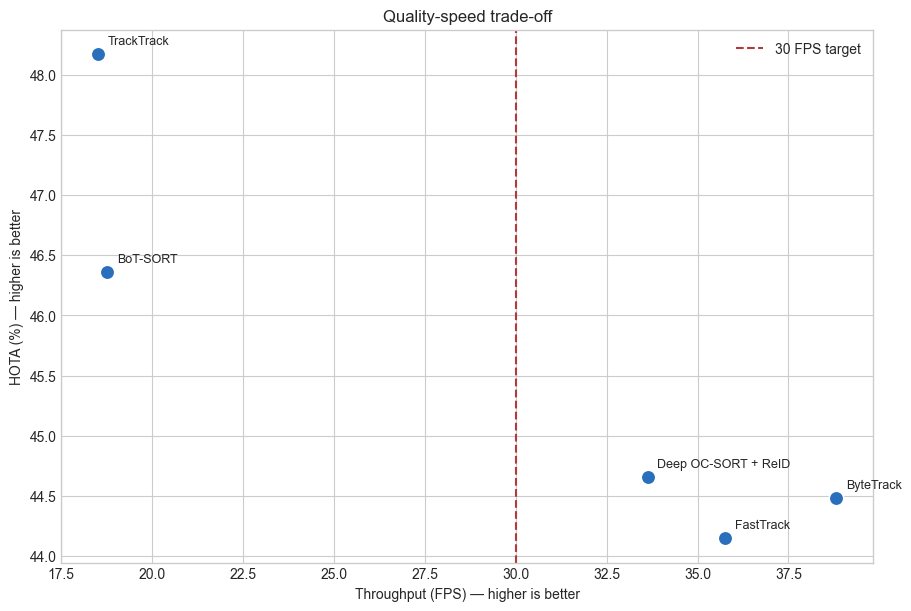

Saved evaluation\results\figures\quality_speed_tradeoff.png


In [10]:
fig, axis = plt.subplots(figsize=(9, 6), constrained_layout=True)
axis.scatter(
    results["Throughput (FPS)"],
    results["HOTA (%)"],
    s=110,
    color="#2a6fbb",
    edgecolor="white",
    linewidth=1.2,
)
for tracker_name, row in results.iterrows():
    axis.annotate(
        tracker_name,
        (row["Throughput (FPS)"], row["HOTA (%)"]),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=9,
    )
axis.axvline(30, color="#b33a3a", linestyle="--", linewidth=1.5, label="30 FPS target")
axis.set_xlabel("Throughput (FPS) — higher is better")
axis.set_ylabel("HOTA (%) — higher is better")
axis.set_title("Quality-speed trade-off")
axis.legend(loc="best")
quality_speed_path = FIGURE_DIR / "quality_speed_tradeoff.png"
fig.savefig(quality_speed_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved {quality_speed_path}")

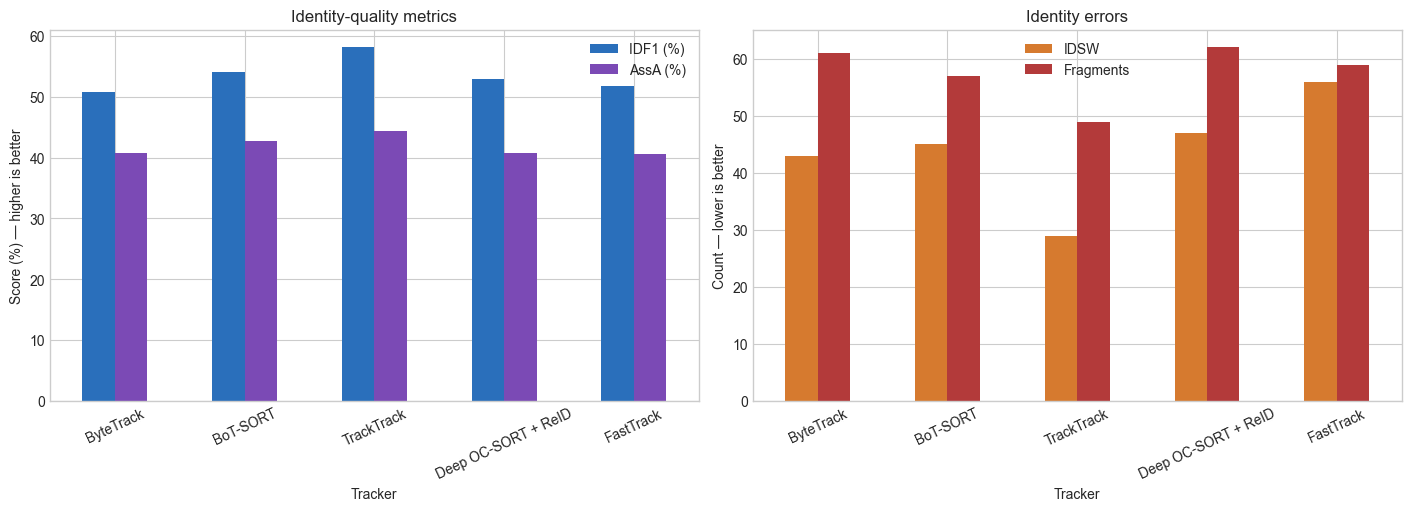

Saved evaluation\results\figures\identity_stability.png


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
results[["IDF1 (%)", "AssA (%)"]].plot.bar(ax=axes[0], color=["#2a6fbb", "#7b4ab5"])
axes[0].set_title("Identity-quality metrics")
axes[0].set_ylabel("Score (%) — higher is better")
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend(loc="best")

results[["IDSW", "Fragments"]].plot.bar(ax=axes[1], color=["#d67a2f", "#b33a3a"])
axes[1].set_title("Identity errors")
axes[1].set_ylabel("Count — lower is better")
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend(loc="best")

identity_stability_path = FIGURE_DIR / "identity_stability.png"
fig.savefig(identity_stability_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved {identity_stability_path}")

### 4.2 Qualitative occlusion demonstration

A single frame cannot demonstrate persistence. Supporting Figure 2 therefore uses the same short frame sequence for ground truth, the tracker with the strongest measured identity result, and the fastest tracker. The images support inspection of ID continuity during low visibility; the quantitative table remains the basis for conclusions.

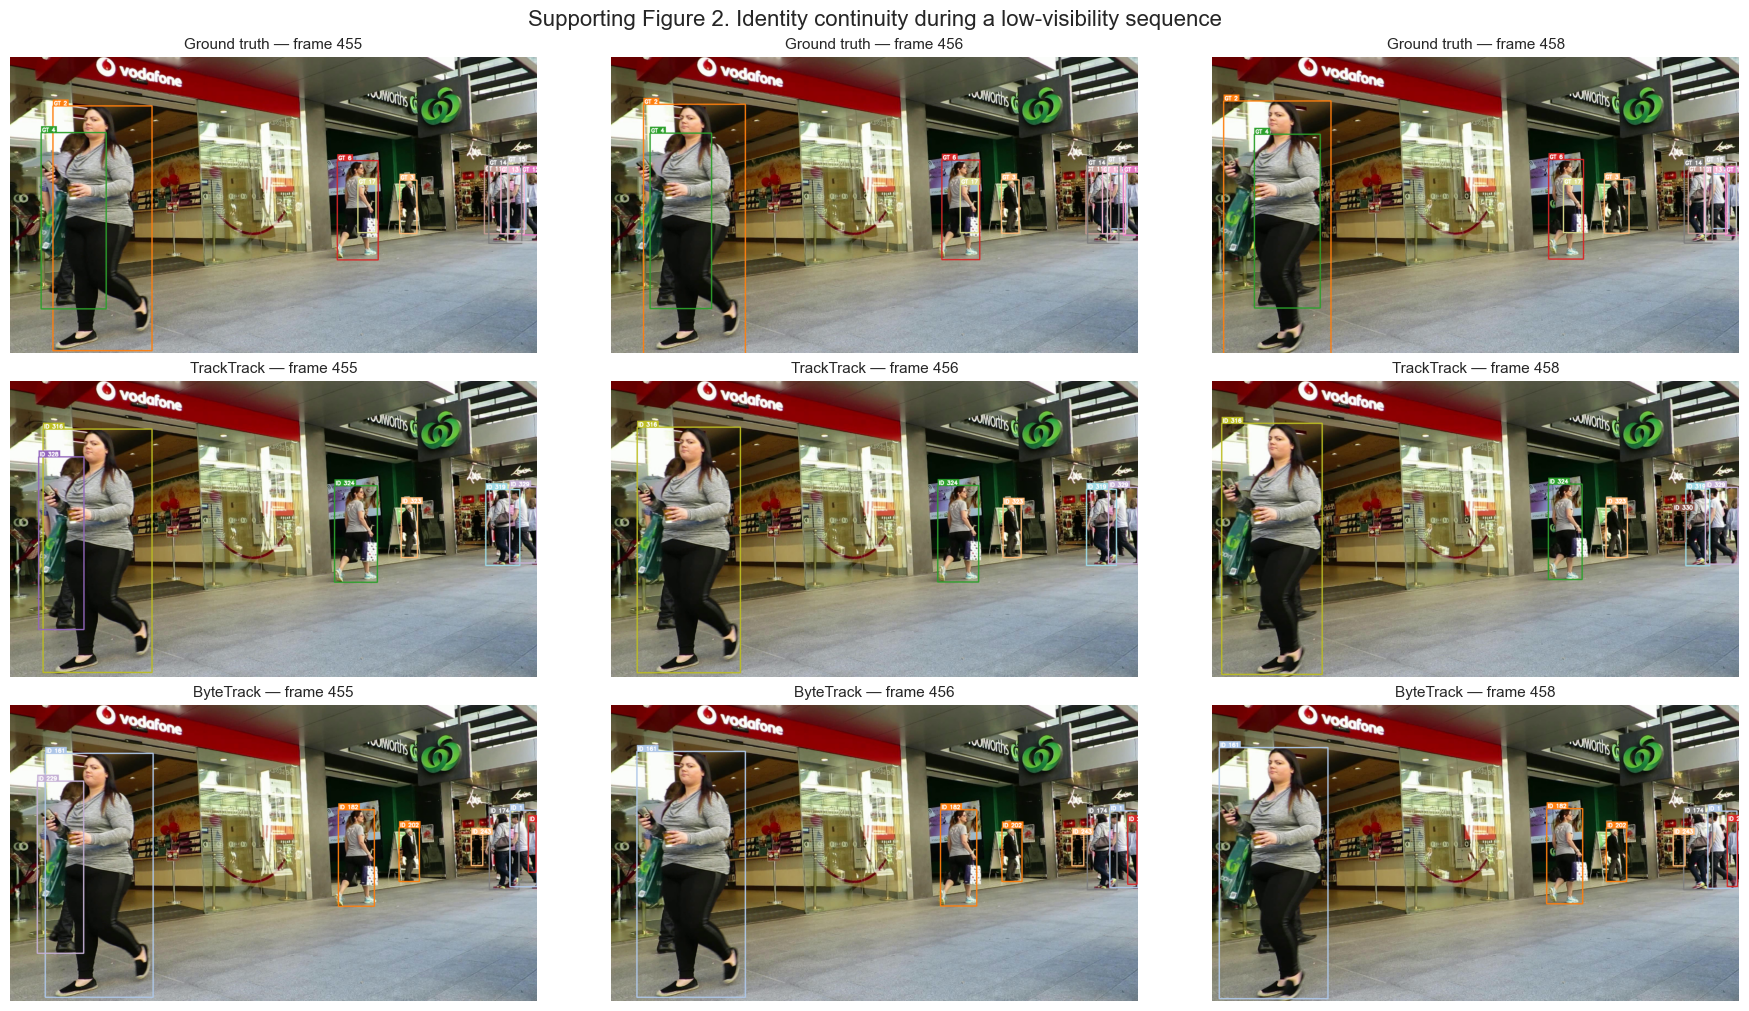

Saved evaluation\results\figures\figure_2_occlusion_tracking_comparison.png


In [12]:
sequence_frames = [455, 456, 458]
quality_tracker = results["IDF1 (%)"].idxmax()
speed_tracker = results["Throughput (FPS)"].idxmax()
gallery_rows = ["Ground truth", quality_tracker, speed_tracker]

fig, axes = plt.subplots(3, 3, figsize=(18, 10), constrained_layout=True)
for row_index, row_name in enumerate(gallery_rows):
    for column_index, frame_number in enumerate(sequence_frames):
        frame = read_video_frame(frame_number)
        if row_name == "Ground truth":
            boxes = ground_truth[ground_truth["frame"] == frame_number]
            annotated = draw_track_boxes(frame, boxes, "GT")
        else:
            boxes = predictions_by_tracker[row_name]
            boxes = boxes[boxes["frame"] == frame_number]
            annotated = draw_track_boxes(frame, boxes, "ID")

        axis = axes[row_index, column_index]
        axis.imshow(annotated)
        axis.set_title(f"{row_name} — frame {frame_number}", fontsize=11)
        axis.axis("off")

fig.suptitle(
    "Supporting Figure 2. Identity continuity during a low-visibility sequence",
    fontsize=16,
)
figure_2_path = FIGURE_DIR / "figure_2_occlusion_tracking_comparison.png"
fig.savefig(figure_2_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved {figure_2_path}")

**Supporting Figure 2.** Frames 455, 456, and 458 occur around the lowest mean ground-truth visibility in the sequence. Ground truth is compared with the executed run’s highest-IDF1 tracker and fastest tracker. The gallery is a qualitative demonstration only: apparent continuity or failure in three frames does not replace sequence-level HOTA, IDF1, AssA, switch, and fragmentation measurements.

## 5 Discussion

The following summary is generated from the current execution so tracker rankings and differences remain aligned with the saved CSV. “Balanced candidate” is an explicitly labelled deployment heuristic: the harmonic mean of HOTA relative to the best HOTA and FPS relative to the fastest FPS. It is not a standard MOT metric and does not replace HOTA or IDF1.

In [13]:
quality_winner = results["HOTA (%)"].idxmax()
identity_winner = results["IDF1 (%)"].idxmax()
fastest_tracker = results["Throughput (FPS)"].idxmax()
fewest_switches = results["IDSW"].idxmin()

relative_quality = results["HOTA (%)"] / results["HOTA (%)"].max()
relative_speed = results["Throughput (FPS)"] / results["Throughput (FPS)"].max()
balanced_score = 2 * relative_quality * relative_speed / (relative_quality + relative_speed)
balanced_candidate = balanced_score.idxmax()

quality_gap = (
    results.loc[quality_winner, "HOTA (%)"]
    - results.drop(index=quality_winner)["HOTA (%)"].max()
)
speed_gap = (
    results.loc[fastest_tracker, "Throughput (FPS)"]
    - results.drop(index=fastest_tracker)["Throughput (FPS)"].max()
)

display(Markdown(f'''
- **Best overall quality:** {quality_winner}, with **{results.loc[quality_winner, 'HOTA (%)']:.2f}% HOTA**, {quality_gap:.2f} percentage points above the next result.
- **Best identity score:** {identity_winner}, with **{results.loc[identity_winner, 'IDF1 (%)']:.2f}% IDF1**.
- **Fewest identity switches:** {fewest_switches}, with **{int(results.loc[fewest_switches, 'IDSW'])} switches**.
- **Fastest tracker:** {fastest_tracker}, at **{results.loc[fastest_tracker, 'Throughput (FPS)']:.2f} FPS**, {speed_gap:.2f} FPS above the next result.
- **Balanced deployment heuristic:** {balanced_candidate}. This choice reflects equal relative weighting of HOTA and throughput; another deployment may weight identity quality or latency differently.
- **30 FPS check:** {int((results['Throughput (FPS)'] >= 30).sum())} of 5 trackers reached an average 30 FPS in this execution.
'''))


- **Best overall quality:** TrackTrack, with **48.17% HOTA**, 1.81 percentage points above the next result.
- **Best identity score:** TrackTrack, with **58.08% IDF1**.
- **Fewest identity switches:** TrackTrack, with **29 switches**.
- **Fastest tracker:** ByteTrack, at **38.81 FPS**, 3.05 FPS above the next result.
- **Balanced deployment heuristic:** ByteTrack. This choice reflects equal relative weighting of HOTA and throughput; another deployment may weight identity quality or latency differently.
- **30 FPS check:** 3 of 5 trackers reached an average 30 FPS in this execution.


The results should be interpreted through the association mechanisms reviewed earlier. A higher-quality but slower tracker may be appropriate for offline analysis, while a lightweight tracker may be preferable for a live laptop camera. Supporting Figure 2 gives a concrete view of low-visibility tracking, but it is not sufficient evidence on its own; the full-sequence identity metrics determine the comparison.

**Limitations.** This experiment uses one short pedestrian sequence, one fixed YOLOv8l detector, a single run per tracker, and laptop-specific timing. The local evaluator excludes official MOTChallenge distractor and ignore-region logic, so its absolute results must not be presented as official benchmark scores. Tracker defaults also represent particular Ultralytics implementations and may differ from the configurations used in the original papers.

## 6 Conclusion

This controlled experiment extends frame-level YOLO detection into persistent multi-object tracking and compares five advanced association strategies under identical conditions. The executed results separate overall tracking quality, identity stability, and runtime rather than treating one metric as universally decisive. The dynamically generated discussion names the strongest quality tracker, fastest tracker, and an explicitly defined quality-speed candidate using the current run rather than hard-coded values.

For deployment, the tracker should be selected according to the application’s frame-rate budget and tolerance for identity errors. A laptop-based live system may prioritise throughput, whereas offline crowd analysis may justify greater association complexity for improved tracking quality.  

The most important next step is evaluation across additional MOT17 sequences with different density, motion, lighting, and camera movement, followed by official ignore-region handling and repeated timing trials.

## References

[1] Y. Zhang et al., “ByteTrack: Multi-Object Tracking by Associating Every Detection Box,” *ECCV*, 2022. https://arxiv.org/abs/2110.06864  
[2] N. Aharon, R. Orfaig, and B.-Z. Bobrovsky, “BoT-SORT: Robust Associations Multi-Pedestrian Tracking,” 2022. https://arxiv.org/abs/2206.14651  
[3] K. Shim, K. Ko, Y. Yang, and C. Kim, “Focusing on Tracks for Online Multi-Object Tracking,” *CVPR*, 2025. https://openaccess.thecvf.com/content/CVPR2025/html/Shim_Focusing_on_Tracks_for_Online_Multi-Object_Tracking_CVPR_2025_paper.html  
[4] G. Maggiolino, A. Ahmad, J. Cao, and K. Kitani, “Deep OC-SORT: Multi-Pedestrian Tracking by Adaptive Re-Identification,” 2023. https://arxiv.org/abs/2302.11813  
[5] H. Hashempoor and Y. D. Hwang, “FastTracker: Real-Time and Accurate Visual Tracking,” 2025. https://arxiv.org/abs/2508.14370  
[6] J. Luiten et al., “HOTA: A Higher Order Metric for Evaluating Multi-Object Tracking,” *International Journal of Computer Vision*, 2021. https://arxiv.org/abs/2009.07736  
[7] MOTChallenge, “MOT17Det Dataset.” https://motchallenge.net/data/MOT17Det/  
[8] Ultralytics, “Multi-Object Tracking with Ultralytics YOLO.” https://docs.ultralytics.com/modes/track/

## Appendix A: Reproducibility Checklist

- [x] Repository commit captured during execution
- [x] Python, CUDA, PyTorch, Ultralytics, OpenCV, and numerical-library versions displayed
- [x] Dataset identified as MOT17-09 with validated frame and annotation counts
- [x] YOLO checkpoint, class filter, confidence threshold, and image size documented
- [x] Exact tracker names and resolved configuration paths displayed
- [x] Fresh model/tracker state used for every run
- [x] Timing boundary and warm-up exclusion documented
- [x] Prediction CSVs, annotated videos, master results, and figures saved
- [x] Evaluator limitations stated explicitly